<a href="https://colab.research.google.com/github/Bnr4/MSIS822-AI-Arabic-Text-Detection/blob/main/MSIS822_AI_Arabic_Text_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets

In [2]:
from datasets import load_dataset

dataset = load_dataset("KFUPM-JRCAI/arabic-generated-abstracts")

README.md:   0%|          | 0.00/8.10k [00:00<?, ?B/s]

data/by_polishing-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.49MB            

data/by_polishing-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/from_title-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.90MB            

data/from_title-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/from_title_and_content-00000-of-000(…): reconstructing file:   0%|          |  0.00B / 7.01MB            

data/from_title_and_content-00000-of-000(…): downloading bytes:           |  0.00B            

Generating by_polishing split:   0%|          | 0/2851 [00:00<?, ? examples/s]

Generating from_title split:   0%|          | 0/2963 [00:00<?, ? examples/s]

Generating from_title_and_content split:   0%|          | 0/2574 [00:00<?, ? examples/s]

In [3]:
print(dataset)

DatasetDict({
    by_polishing: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2851
    })
    from_title: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2963
    })
    from_title_and_content: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2574
    })
})


In [4]:
print(dataset["by_polishing"].features)

{'original_abstract': Value('string'), 'allam_generated_abstract': Value('string'), 'jais_generated_abstract': Value('string'), 'llama_generated_abstract': Value('string'), 'openai_generated_abstract': Value('string')}


In [5]:
dataset["by_polishing"][0]

{'original_abstract': 'كثيرا ما ارتبطت المصادر التاريخية في الأندلس خاصة منها كتب التراجم والفهرسات والبرامج وغيرها بدراسة حياة العلماء والرواة والقضاة والساسة ؛ وقد تطورت هذه المادة حتى ترك لنا المؤلفون الأندلسيون سلسلة متواصلة الحلقات من كتب التـراجم كالصلة لابن بشكوال ، وصلة الصلة لابن الزبير، والتكملة لكتاب الصلة لابن الآبار، والذيل والتكملة لكتابي الموصول والصلة لابن عبد الملك المراكشي إضافة إلى الإحاطة في أخبار غرناطة لابن الخطيب ، إلا أنها لم تنس أن تشير في ثنايا أو بالأحرى في خواتم هذه المؤلفات إلى فئة المرأة العالمة التي ساهمت في الإنتاج الفكري والحضاري الأندلسي. ومن خلالها سنسعى إلى الوقوف على حالة التعليم عند المرأة الأندلسية ، وكيف كانت تأخذ فنون العلم. وما مدى إسهامها في الفكر التربوي والإنتاج الفكري الأندلسيين ؟.',
 'allam_generated_abstract': 'يتناول هذا البحث موضوع التعليم بين النساء الأندلسيات من خلال دراسة المصادر التاريخية المتعلقة بتراجم العلماء والرواة والقضاة والساسة. يركز البحث على إبراز دور المرأة العالمة ومساهمتها في الإنتاج الفكري والحضاري الأندلسي. من خلال تح

In [6]:
import pandas as pd

for split_name in dataset.keys():
    df = dataset[split_name].to_pandas()
    print(f"\n{split_name}:")
    print(df.isnull().sum())


by_polishing:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64

from_title:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64

from_title_and_content:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64


In [7]:
for split_name in dataset.keys():
    df = dataset[split_name].to_pandas()
    print(f"{split_name}: {df.duplicated().sum()} duplicate rows")

by_polishing: 0 duplicate rows
from_title: 0 duplicate rows
from_title_and_content: 0 duplicate rows


In [8]:
human_count = 0
ai_count = 0

for split_name in dataset.keys():
    rows = len(dataset[split_name])
    human_count += rows
    ai_count += rows * 4

print("Human texts:", human_count)
print("AI-generated texts:", ai_count)
print("Total texts:", human_count + ai_count)

Human texts: 8388
AI-generated texts: 33552
Total texts: 41940


In [9]:
for split_name in dataset.keys():
    df = dataset[split_name].to_pandas()

    empty_counts = (df.fillna("").apply(
        lambda col: col.str.strip().eq("")
    )).sum()

    print(f"\n{split_name}:")
    print(empty_counts)


by_polishing:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64

from_title:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64

from_title_and_content:
original_abstract            0
allam_generated_abstract     0
jais_generated_abstract      0
llama_generated_abstract     0
openai_generated_abstract    0
dtype: int64


In [10]:
total = human_count + ai_count

print(f"Human: {human_count} ({human_count / total * 100:.2f}%)")
print(f"AI-generated: {ai_count} ({ai_count / total * 100:.2f}%)")

Human: 8388 (20.00%)
AI-generated: 33552 (80.00%)


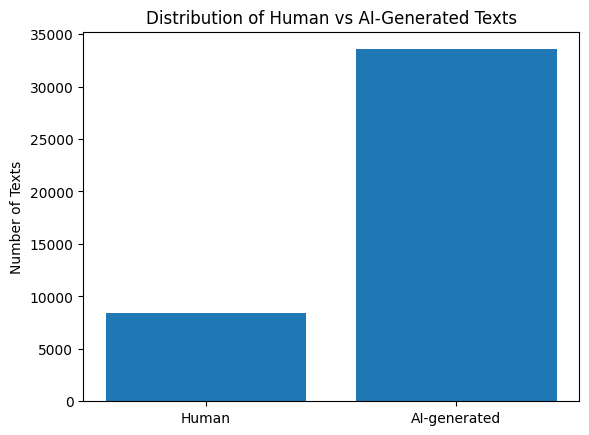

In [11]:
import matplotlib.pyplot as plt

labels = ['Human', 'AI-generated']
counts = [human_count, ai_count]

plt.bar(labels, counts)
plt.title('Distribution of Human vs AI-Generated Texts')
plt.ylabel('Number of Texts')
plt.show()

# Initial Data Exploration

The dataset has three subsets: `by_polishing`, `from_title`, and `from_title_and_content`. Together, they contain 8,388 records.

Each record has one original abstract and four AI-generated versions. After counting all texts, there are 8,388 human texts and 33,552 AI-generated texts, which gives a total of 41,940 texts.

I also checked the dataset for missing values, empty texts, and duplicate rows. No issues were found in these checks.

The data is not balanced between the two classes. Human texts represent 20% of the data, while AI-generated texts represent 80%. This is something that should be considered in the next stages of the project.